# Step 2 — EDA on the Ames history (2006–2009)

Questions from the README: price by year, by `Overall Qual`, by `Year Built`, by neighbourhood; how many
homes sell above $300k; which columns are not known when a home is listed; and why the fitness scores on
past years instead of a random split.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "PROJECT_BRIEF.md").exists():
    ROOT = ROOT.parent

def load(path):
    # "None" and "NA" are real categories here (no masonry, no garage), not missing values
    return pd.read_csv(path, keep_default_na=False, na_values=[""])

hist = load(ROOT / "work/exploration/train.csv")
listings = load(ROOT / "data/ames_2010_listings.csv")
print("history:", hist.shape, " 2010 listings:", listings.shape)

def summary(groups):
    s = groups.SalePrice
    return pd.DataFrame({"homes": s.size(), "median": s.median(), "p10": s.quantile(0.1),
                         "p90": s.quantile(0.9)}).round(0)

history: (2589, 80)  2010 listings: (341, 78)


## Sale price

count      2589.0
mean     181876.0
std       80505.0
min       13100.0
25%      129900.0
50%      161500.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64
above $300,000: 210
above $400,000: 60
above $500,000: 15


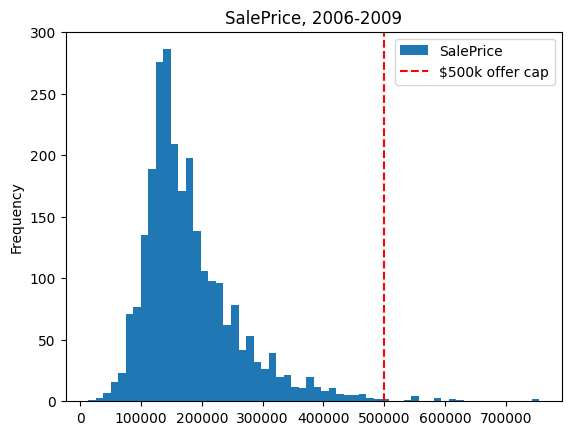

In [2]:
print(hist.SalePrice.describe().round(0))
for t in (300_000, 400_000, 500_000):
    print(f"above ${t:,}: {(hist.SalePrice > t).sum()}")

hist.SalePrice.plot.hist(bins=60, title="SalePrice, 2006-2009")
plt.axvline(500_000, color="red", ls="--", label="$500k offer cap")
plt.legend(); plt.show()

## By year sold

Is the market moving? If prices drift, a model trained on earlier years will be off on later ones.

In [3]:
summary(hist.groupby("Yr Sold"))

,homes,median,p10,p90
Yr Sold,,,,
2006,625,159500.0,105000.0,286961.0
2007,694,165125.0,112150.0,285000.0
2008,622,161000.0,105000.0,285900.0
2009,648,160850.0,104970.0,276250.0


## By overall quality

,homes,median,p10,p90
Overall Qual,,,,
1,4,50150.0,20960.0,75350.0
2,11,57625.0,35311.0,63900.0
3,35,81000.0,55800.0,114000.0
4,191,106500.0,79275.0,140000.0
5,726,133000.0,104000.0,165000.0
6,645,160000.0,118440.0,207500.0
7,535,198500.0,155000.0,260000.0
8,313,266000.0,201300.0,350000.0
9,98,358142.0,284250.0,468600.0


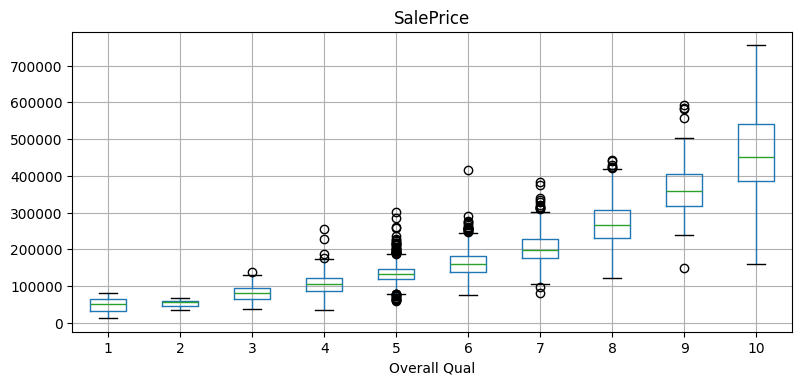

In [4]:
by_qual = summary(hist.groupby("Overall Qual"))
display(by_qual)
hist.boxplot(column="SalePrice", by="Overall Qual", figsize=(9, 4)); plt.suptitle(""); plt.show()

## By year built

In [5]:
bins = [1800, 1920, 1950, 1970, 1990, 2000, 2011]
summary(hist.groupby(pd.cut(hist["Year Built"], bins), observed=True))

,homes,median,p10,p90
Year Built,,,,
"(1800, 1920]",203,120000.0,79920.0,179320.0
"(1920, 1950]",388,126000.0,80350.0,191900.0
"(1950, 1970]",612,139925.0,107090.0,185000.0
"(1970, 1990]",401,156000.0,116000.0,241500.0
"(1990, 2000]",319,204750.0,160000.0,313400.0
"(2000, 2011]",666,227778.0,164245.0,377463.0


## By neighbourhood

,homes,median,p10,p90
Neighborhood,,,,
MeadowV,30,91500.0,75171.0,129540.0
IDOTRR,84,107500.0,59688.0,146520.0
BrDale,27,108000.0,89300.0,120700.0
OldTown,210,119082.0,84500.0,160100.0
Blueste,8,123950.0,116050.0,165700.0
Edwards,171,125000.0,84000.0,179000.0
BrkSide,97,126000.0,79740.0,164940.0
Sawyer,128,135000.0,111400.0,165000.0
Landmrk,1,137000.0,137000.0,137000.0


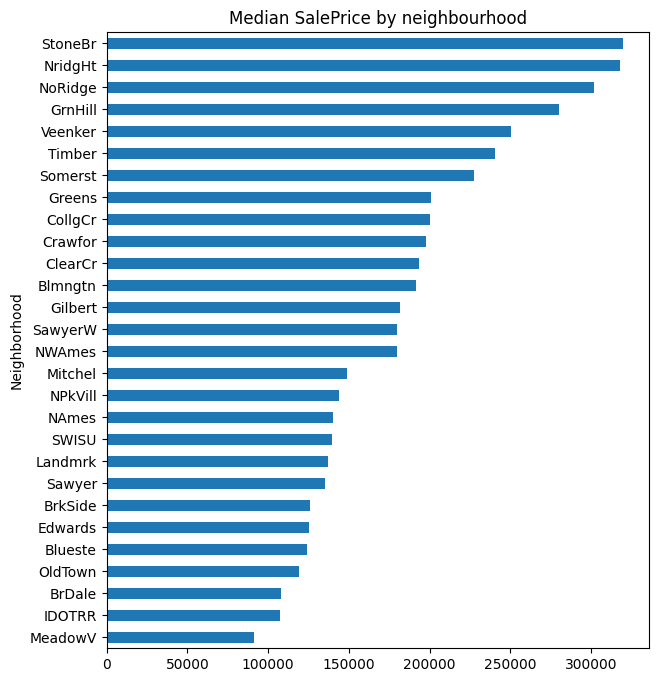

In [6]:
by_nbhd = summary(hist.groupby("Neighborhood")).sort_values("median")
display(by_nbhd)
by_nbhd["median"].plot.barh(figsize=(7, 8), title="Median SalePrice by neighbourhood"); plt.show()

## Size, and the very large homes

The skeleton has a gene that drops homes over 4,000 sq ft from training.

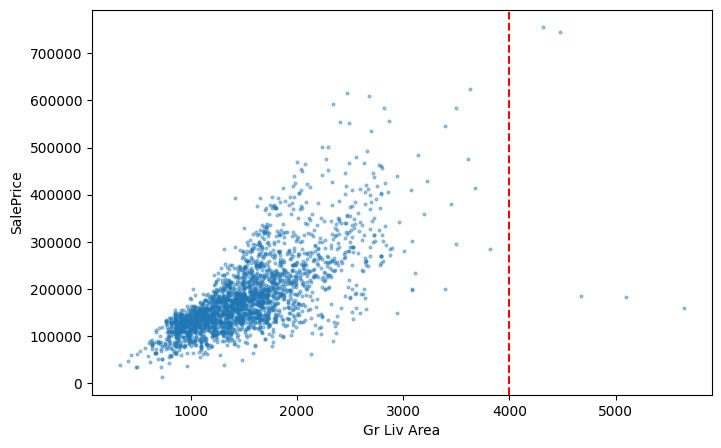

,Gr Liv Area,SalePrice,Sale Condition,Neighborhood
1157,5642,160000,Partial,Edwards
1419,4476,745000,Abnorml,NoRidge
1426,4316,755000,Normal,NoRidge
1839,5095,183850,Partial,Edwards
1840,4676,184750,Partial,Edwards


In [7]:
ax = hist.plot.scatter(x="Gr Liv Area", y="SalePrice", s=4, alpha=0.4, figsize=(8, 5))
ax.axvline(4000, color="red", ls="--"); plt.show()
hist.loc[hist["Gr Liv Area"] > 4000, ["Gr Liv Area", "SalePrice", "Sale Condition", "Neighborhood"]]

## Feature boundary: the sale columns

Which columns exist in the history but not in the 2010 listings?

In [8]:
print("only in history:", sorted(set(hist.columns) - set(listings.columns)))
print("only in 2010:   ", sorted(set(listings.columns) - set(hist.columns)))

only in history: ['Sale Condition', 'Sale Type', 'SalePrice']
only in 2010:    ['ListingID']


In [9]:
display(summary(hist.groupby("Sale Condition")))
display(summary(hist.groupby("Sale Type")))
pd.crosstab(hist["Yr Sold"], hist["Sale Condition"])

,homes,median,p10,p90
Sale Condition,,,,
Abnorml,168,130500.0,76050.0,211400.0
AdjLand,12,110000.0,82000.0,127500.0
Alloca,22,152123.0,109435.0,256445.0
Family,43,144800.0,93000.0,245800.0
Normal,2112,158750.0,108000.0,269500.0
Partial,232,248614.0,167300.0,405460.0


,homes,median,p10,p90
Sale Type,,,,
COD,75,128500.0,83960.0,177600.0
CWD,12,160750.0,136450.0,219950.0
Con,3,155000.0,127000.0,290200.0
ConLD,20,113950.0,57362.0,202900.0
ConLI,8,122000.0,85500.0,370085.0
ConLw,7,95000.0,75000.0,209300.0
New,227,250000.0,169988.0,408283.0
Oth,5,116050.0,85400.0,139640.0
VWD,1,137000.0,137000.0,137000.0


Sale Condition,Abnorml,AdjLand,Alloca,Family,Normal,Partial
Yr Sold,,,,,,
2006,57,6,2,11,463,86
2007,25,4,5,15,555,90
2008,45,2,5,8,533,29
2009,41,0,10,9,561,27


In [10]:
# Mo Sold: is there a season effect, and what does the 2010 file contain?
display(summary(hist.groupby("Mo Sold")))
listings[["Yr Sold", "Mo Sold"]].value_counts().sort_index()

,homes,median,p10,p90
Mo Sold,,,,
1,97,165500.0,103000.0,319500.0
2,107,167000.0,110600.0,263400.0
3,184,159948.0,97150.0,278650.0
4,207,151500.0,102600.0,249400.0
5,316,158000.0,105750.0,256400.0
6,423,162500.0,110500.0,288800.0
7,441,161900.0,110000.0,284700.0
8,233,165000.0,108100.0,298980.0
9,161,177000.0,95000.0,311872.0


Yr Sold  Mo Sold
2010     1          26
         2          26
         3          48
         4          72
         5          79
         6          82
         7           8
Name: count, dtype: int64

**Decisions** (written up in `work/framing.md`):

| Column | Keep / drop | Reason |
|---|---|---|
| `Sale Type` | Drop | Set when the sale is signed; not in the 2010 listings |
| `Sale Condition` | Drop | The outcome of the deal (foreclosure $131k, new home $249k); not in the 2010 listings |
| `Mo Sold` | Drop | Month the sale closed, unknown at offer time; no season pattern anyway |
| `Yr Sold` | Drop as a feature, keep for folds | 2010 is outside the training range and prices were flat |

## Evaluation: past-year folds

The fitness fits on the years before Y and offers on Y. How big is each fold?

In [11]:
for y in (2007, 2008, 2009):
    print(f"Y={y}: fit on {(hist['Yr Sold'] < y).sum():4d} sales ({hist['Yr Sold'].min()}-{y-1}), "
          f"offer on {(hist['Yr Sold'] == y).sum()}")
print("2010 test:", len(listings), "listings, prices held by the teacher")

Y=2007: fit on  625 sales (2006-2006), offer on 694
Y=2008: fit on 1319 sales (2006-2007), offer on 622
Y=2009: fit on 1941 sales (2006-2008), offer on 648
2010 test: 341 listings, prices held by the teacher


**Why past years and not a random split?** (written up in `work/design.md`)

In early 2010 we price homes later in time than anything we have seen: fitting on earlier years and
offering on a later one is the same situation. A random split trains on later sales to price earlier
homes, so it leaks the future and reports too-good errors. It would also hide the change in the housing
mix (new-home sales fell from ~90 to ~28 a year after 2007). Three years rather than one, so a policy
that only works in one market does not win.